# Más allá: calibrar antes de 2023, evaluar marzo de 2023 y leer la tensión inversa como un multiplicador

- **Nivel:** 4, Más allá del estado del arte
- **Requisitos previos:** los cuadernos 02, 04, 06 y 07 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- enunciar la afirmación BS-11 del producto (la tensión de liquidez inversa como un multiplicador de fuga, con una regla de rechazo, evaluada frente a una corrida rotulada) y decir qué deja abierto el estado del arte;
- reproducir el multiplicador de las tres bases con el motor y comprobar que es un umbral, que el motor rechaza lo que no puede acotar y que un escalón en el período de supervivencia no rompe el viaje de ida y vuelta;
- ver la guarda de fuga de información en acción (calibrar antes de 2023, evaluar en 2023) y qué dice la evaluación;
- leer el multiplicador como una distancia: qué tan lejos estuvo la corrida de Silicon Valley Bank de la meta de 30 días.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Cinco documentos versionados del caso C16, todos en `data/derived/C16/` (agregados reales del reporte de llamada de la FDIC del banco que quebró el 2023-03-10 hasta el 2022-12-31, comportamiento y depósitos sintéticos, clase de licencia `mirror-allowed`):

- `reverse-stress.json`: el multiplicador de las tres bases con una meta de 30 días, con la curva, el viaje de ida y vuelta y el rechazo.
- `fast-run.json`: la variante de corrida rápida y su evaluación frente a las corridas de la Tabla A.1 (BCBS, 2023).
- `models-svb-liquidity.json`: la división de calibración y el generador de depositantes con su verdad conocida.
- `list-adverse.json` y `list-extreme.json`: las escaleras de las dos bases LiST.

Los montos están en miles de USD. La corrida observada es la de Silicon Valley Bank, 85% de los depósitos en 2 días (BCBS, 2023, Tabla A.1; Federal Reserve, 2023).

In [2]:
# Cargar los cinco documentos versionados (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
documents = {}
for name in ("reverse-stress", "fast-run", "models-svb-liquidity", "list-adverse", "list-extreme"):
    documents[name] = json.loads((ROOT / "data" / "derived" / "C16" / f"{name}.json").read_text(encoding="utf-8"))
    print(name, "| calculado con riskvalidation", documents[name]["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

reverse_doc = documents["reverse-stress"]
bases = {base["base_id"]: base for base in reverse_doc["outputs"]["bases"]}
conventions = reverse_doc["outputs"]["conventions"]
rows = {row["variant"]: row for row in conventions["variant_scenarios"]["rows"]}
target = reverse_doc["outputs"]["target"]["days"]
print("meta (días):", target, "| bases:", list(bases))

reverse-stress | calculado con riskvalidation 0.8.1 | instalado 0.8.1
fast-run | calculado con riskvalidation 0.8.1 | instalado 0.8.1
models-svb-liquidity | calculado con riskvalidation 0.8.1 | instalado 0.8.1
list-adverse | calculado con riskvalidation 0.8.1 | instalado 0.8.1
list-extreme | calculado con riskvalidation 0.8.1 | instalado 0.8.1
meta (días): 30 | bases: ['list-adverse', 'list-extreme', 'fast-run']


## Método

### Paso 1: el multiplicador de las tres bases

La tensión inversa pide el menor multiplicador $m^*$ de las tasas diarias de fuga (cada tasa limitada a 1 como máximo) con el que el período de supervivencia cae a la meta $T$ (cuaderno 06):

$$m^* = \min\{\, m \in [1, m_{\max}] : \mathrm{SP}(m) \le T \,\}, \qquad \mathrm{SP}(m^*) \le T < \mathrm{SP}(m^* - 10^{-6})$$

La celda siguiente reconstruye los tres escenarios base a partir de los segmentos versionados (la corrida rápida con la tasa calibrada en las filas anteriores a 2023, como en el cuaderno 04), construye el CBC efectivo del cuaderno 06 y resuelve con la meta del documento. Compara con las soluciones versionadas e imprime la razón cuando el motor rechaza.

In [3]:
# Reconstruir las tres bases, construir la CBC efectiva y resolver el multiplicador en la meta del documento
from riskvalidation.liquidity.reverse import max_multiplier, solve_multiplier, survival_vs_multiplier
from riskvalidation.liquidity.runoff import LIST_PARAMETERS, TABLE_A1
from riskvalidation.liquidity.scenarios import Scenario, anchor_from_observation, compose_scenario, fast_run_scenario, list_scenario
from riskvalidation.validation.liquidity import reverse_stress_round_trip

pre_2023 = [run for run in TABLE_A1 if run.year < 2023]
fit = fast_run_scenario(pre_2023, "maximum-implied-daily-rate", scored=True)

built = {}
for base_id, severity in (("list-adverse", "adverse"), ("list-extreme", "extreme"), ("fast-run", "adverse")):
    lad = documents[base_id]["outputs"]["path"]["ladder"]
    row = rows[base_id]
    segments = {s["segment"]: (s["list_class"], s["opening_balance"]) for s in lad["segments"]}
    if base_id == "fast-run":
        rest = compose_scenario(row["scenario_family"], row["phase"], list_scenario(severity), {k: v for k, v in segments.items() if k != "non-operational-corporate"}, row["horizon_days"])
        corporate = compose_scenario(row["scenario_family"], row["phase"], fit, {"non-operational-corporate": ("concentrated-uninsured", segments["non-operational-corporate"][1])}, row["horizon_days"])
        by_id = {s.segment_id: s for s in (*rest.segments, *corporate.segments)}
        scenario = Scenario(row["scenario_family"], row["phase"], row["horizon_days"], tuple(by_id[k] for k in segments))
    else:
        scenario = compose_scenario(row["scenario_family"], row["phase"], list_scenario(severity), segments, row["horizon_days"])
    contractual = np.array(lad["total_outflows"]) - scenario.outflows().sum(axis=0)
    effective_cbc = np.array(lad["cbc_total"]) + np.cumsum(lad["total_inflows"]) - np.cumsum(contractual)
    built[base_id] = (scenario, effective_cbc)

words = {"solved": "resuelta", "refused": "rechazada"}
for base_id, (scenario, effective_cbc) in built.items():
    answer = solve_multiplier(scenario, effective_cbc, target)
    committed = bases[base_id]["solved"]
    print(f"{base_id:13s} | tope: {max_multiplier(scenario):9.4f} | {words[answer.status]} | m* = {'ninguno' if answer.multiplier is None else answer.multiplier} | versionado: {'ninguno' if committed['multiplier'] is None else committed['multiplier']} | igual: {'sí' if answer.multiplier == committed['multiplier'] else 'no'}")
    if answer.status == "refused":
        print("   ", committed["refusal_reason"]["es"])

list-adverse  | tope:  145.2346 | resuelta | m* = 2.118175 | versionado: 2.118175 | igual: sí
list-extreme  | tope:   93.8765 | resuelta | m* = 1.383141 | versionado: 1.383141 | igual: sí
fast-run      | tope:   18.4303 | rechazada | m* = ninguno | versionado: ninguno | igual: sí
    El objetivo de 30 días no es menor que el horizonte de 5 días: no existe un intervalo.


### Paso 2: un escalón en el período de supervivencia

El período de supervivencia es un día entero, y un CBC que crece en los primeros días puede hacerlo saltar por encima de la meta: ningún multiplicador da entonces exactamente la meta. El motor devuelve el **umbral** (el menor $m$ con $\mathrm{SP}(m) \le T$), informa el período de supervivencia en él y justo por debajo, y la prueba de ida y vuelta acepta el escalón mientras la meta se alcance en $m^*$ y no justo por debajo. La base de corrida rápida tiene un horizonte de 5 días, así que la meta del documento (30 días) se rechaza; las metas bajo el horizonte se resuelven. La celda siguiente le pide a la base de corrida rápida metas de 5, 4, 3 y 1 días (una exploración, no filas versionadas) y corre la prueba de ida y vuelta sobre cada respuesta.

In [4]:
# Metas de 5, 4, 3 y 1 días sobre la base de la corrida rápida, y la prueba de ida y vuelta de cada respuesta
scenario, effective_cbc = built["fast-run"]
print("horizonte de la base (días):", scenario.horizon, "| tope:", round(max_multiplier(scenario), 6))
for days in (5, 4, 3, 1):
    answer = solve_multiplier(scenario, effective_cbc, days)
    if answer.status == "refused":
        print(f"meta {days} | {words[answer.status]} | m* = {'ninguno' if answer.multiplier is None else answer.multiplier}")
        continue
    test = reverse_stress_round_trip(answer.multiplier, answer.survival_at_multiplier, days, 0.0, survival_just_below=answer.survival_just_below)
    print(f"meta {days} | {words[answer.status]} | m* = {'ninguno' if answer.multiplier is None else answer.multiplier} | supervivencia en m*: {answer.survival_at_multiplier} | justo debajo: {answer.survival_just_below.day} | ida y vuelta: {test.statistic} {test.light.value}")

horizonte de la base (días): 5 | tope: 18.430329
meta 5 | rechazada | m* = ninguno
meta 4 | resuelta | m* = 2.06764 | supervivencia en m*: 4 | justo debajo: 5 | ida y vuelta: 0.0 green
meta 3 | resuelta | m* = 2.669936 | supervivencia en m*: 1 | justo debajo: 4 | ida y vuelta: 0.0 green
meta 1 | resuelta | m* = 2.669936 | supervivencia en m*: 1 | justo debajo: 4 | ida y vuelta: 0.0 green


### Paso 3: calibrar antes de 2023, evaluar en marzo de 2023

La tasa de la corrida rápida es un estadístico de las tasas diarias implícitas de la Tabla A.1, $q_i = 1-(1-F_i)^{1/n_i}$, y la regla del documento es el máximo. El protocolo está libre de fuga de información por construcción: la calibración usa las cuatro filas anteriores a 2023, el motor rechaza una fila de 2023 en una llamada evaluada, y las filas de 2023 son contra lo que se evalúa la variante; la observación de Silicon Valley Bank es un ancla rotulada (`forecast_claim` es falso), nunca un pronóstico. La celda siguiente muestra la calibración, el rechazo y la evaluación versionada de la variante sobre las filas que su escalera de 5 días puede evaluar.

In [5]:
# La calibración con las filas anteriores a 2023, el rechazo de una fila de 2023 y la evaluación versionada de la corrida rápida
calibration = documents["models-svb-liquidity"]["fit"]["calibration"]
print("calibrada con:", calibration["split"]["calibrated_on"])
print("evaluada con:", calibration["split"]["scored_on"])
anchor = anchor_from_observation(0.85, 2)
print("ancla del motor (tasa diaria implícita, afirmación de pronóstico):", round(anchor["implied_daily_rate"], 6), ("sí" if anchor["forecast_claim"] else "no"))
print("tasa ajustada:", round(fit.daily_rate, 8), "| versionada:", round(calibration["fitted_daily_rate"]["value"], 8), "| afirmación de pronóstico del ancla:", ("sí" if calibration["anchor"]["forecast_claim"] else "no"))
try:
    fast_run_scenario(list(TABLE_A1), "maximum-implied-daily-rate", scored=True)
except ValueError:
    print("una llamada marcada como evaluada con una fila de 2023 es rechazada por el motor (ValueError)")

roles = {"calibration": "calibración", "scored": "evaluada"}
print(f"{'fila':22s}{'rol':>14s}{'observada':>14s}{'modelada':>14s}{'error':>10s}")
for entry in documents["fast-run"]["outputs"]["scoring"]["table_a1_scoring"]:
    if entry["modelled_share"] is not None:
        print(f"{entry['row_id']:22s}{roles[entry['role']]:>14s}{entry['observed_share']:14.2f}{entry['modelled_share']:14.4f}{entry['error']:10.4f}")
for entry in documents["fast-run"]["tests"]:
    if entry["test_id"] == "liq.runoff_adequacy_back_test":
        print("contrastación:", entry["segment"], "| razón:", round(entry["statistic"], 6), entry["light"], "| calculada con", documents["fast-run"]["provenance"]["riskvalidation_version"])

calibrada con: ['icesave-2008', 'northern-rock-2007', 'wamu-2008', 'indymac-2008']
evaluada con: ['svb-2023', 'first-republic-2023', 'svb-uk-2023', 'credit-suisse-2023', 'signature-2023']
ancla del motor (tasa diaria implícita, afirmación de pronóstico): 0.612702 no
tasa ajustada: 0.05425839 | versionada: 0.05425839 | afirmación de pronóstico del ancla: no
una llamada marcada como evaluada con una fila de 2023 es rechazada por el motor (ValueError)
fila                             rol     observada      modelada     error
svb-2023                    evaluada          0.85        0.1708    0.6792
svb-uk-2023                 evaluada          0.30        0.1263    0.1737
signature-2023              evaluada          0.20        0.1263    0.0737
northern-rock-2007       calibración          0.20        0.2528   -0.0528
contrastación: board-stated-share | razón: 0.200976 red | calculada con 0.8.1
contrastación: call-report-dep | razón: 0.214124 red | calculada con 0.8.1


## Estado del arte

- **Escenarios hacia adelante.** La prueba de tensión de liquidez de 2019 del BCE fija primero los escenarios (tasas diarias suaves compuestas por severidad) e informa el período de supervivencia que dan (BCE, 2019, nota metodológica y anexo de resultados).
- **Variedad de escenarios.** El Principio 10 de los principios de Basilea pide pruebas de tensión en muchos escenarios, individualmente y en combinación (BCBS, 2008); no dice cómo encontrar el escenario que quiebra a un banco dado.
- **La evidencia de 2023.** El informe sobre la turbulencia de 2023 dice que los supuestos de velocidad fueron reajustados por corridas como el 85% de los depósitos en 2 días y lista como preguntas abiertas métricas como una capacidad de contrapeso a cinco días y el período de supervivencia (BCBS, 2023); la Reserva Federal encontró que la prueba de tensión interna de liquidez del banco se apoyaba en referencias de pares no comparables (Federal Reserve, 2023).
- **La tensión inversa en la investigación.** El dosier de investigación lista la tensión de liquidez inversa como el último peldaño de su escalera de modelos de liquidez ("el multiplicador de fuga con el que el período de supervivencia cae bajo una meta, por ejemplo 30 días") sin un caso medido, y no encontró ninguna herramienta que la implemente (UNVERIFIED más allá de la búsqueda del dosier).

## Más allá del estado del arte

**BS-11**, tal como lo enuncia el SDD: el producto responde la pregunta inversa con un número que tiene tres propiedades que el estado del arte deja abiertas.

1. **Un umbral, no una estimación.** El multiplicador de las tasas diarias de fuga con el que el período de supervivencia cae por primera vez a la meta, limitado para que ninguna tasa pase de 1, con el período de supervivencia en él y justo por debajo (pasos 1 y 2);
2. **Una regla de rechazo.** Una meta que no puede acotarse (no menor que el horizonte, ya alcanzada en la base, inalcanzable bajo el tope) se rechaza con su razón y no se devuelve ningún número (paso 1, la corrida rápida; paso 2);
3. **Una corrida resguardada y rotulada.** La base de corrida rápida se calibra solo con las filas anteriores a 2023, el motor rechaza una fila de 2023 en una llamada evaluada, y las filas de 2023 la evalúan, con la observación de Silicon Valley Bank como ancla y nunca como pronóstico (paso 3).

La evidencia es el cálculo de arriba, que reproduce los documentos versionados con el motor. Lo que agrega es una forma de leer la distancia entre una prueba de tensión y una corrida real: el multiplicador. La celda siguiente calcula esa distancia. Para cada base LiST, $m_{\mathrm{SVB}}$ es el multiplicador que lleva la tasa de la clase corporativa no asegurada a la tasa diaria implícita de Silicon Valley Bank, $m_{\mathrm{SVB}} = q_{\mathrm{SVB}} / q_{\text{clase}}$; el motor da el período de supervivencia bajo él, y la razón $m_{\mathrm{SVB}} / m^*$ dice cuántas veces más lejos está la corrida de 2023 que la meta de 30 días.

In [6]:
# El multiplicador que lleva la tasa LiST de la clase corporativa no asegurada a la tasa de SVB, contra el multiplicador umbral
svb = next(run for run in TABLE_A1 if run.row_id == "svb-2023")
corporate = "non-operational-non-financial-corporates"
distance = {}
print("tasa diaria implícita de SVB:", round(svb.implied_daily_rate, 6))
for base_id, severity in (("list-adverse", "adverse"), ("list-extreme", "extreme")):
    scenario, effective_cbc = built[base_id]
    m_star = solve_multiplier(scenario, effective_cbc, target).multiplier
    m_svb = svb.implied_daily_rate / LIST_PARAMETERS[severity]["open_maturity"][corporate]
    at_svb = survival_vs_multiplier(scenario, effective_cbc, np.array([1.0, m_svb]))[1]
    distance[base_id] = (m_star, m_svb)
    print(f"{base_id:13s} | m* = {m_star} | m_SVB = {m_svb:.4f} | tope: {max_multiplier(scenario):.4f} | período de supervivencia en m_SVB (día): {at_svb.day} | m_SVB / m* = {m_svb / m_star:.2f}")

tasa diaria implícita de SVB: 0.612702
list-adverse  | m* = 2.118175 | m_SVB = 88.9855 | tope: 145.2346 | período de supervivencia en m_SVB (día): 1 | m_SVB / m* = 42.01
list-extreme  | m* = 1.383141 | m_SVB = 57.5183 | tope: 93.8765 | período de supervivencia en m_SVB (día): 1 | m_SVB / m* = 41.59


La verificación con verdad conocida del estimador detrás de la corrida rápida también está versionada: el generador de depositantes del documento de modelos, con una verdad exacta, se verificó con 20.000 simulaciones con semilla, y la prueba `liq.runoff_vs_generator_truth` del documento de corrida rápida lee su resultado (el cuaderno 04 reejecuta una versión pequeña). La última celda imprime ambos y dibuja la respuesta: a la izquierda, el período de supervivencia frente al multiplicador para las tres bases con los umbrales marcados; a la derecha, el multiplicador umbral de cada base LiST frente al multiplicador de la corrida de 2023, en un eje logarítmico.

verificación del generador: simulaciones, mayor error, error estándar, dentro del error: 20000 0.00026 0.000484 sí
fila de prueba: mayor distancia en errores estándar y semáforo: 0.5369 green


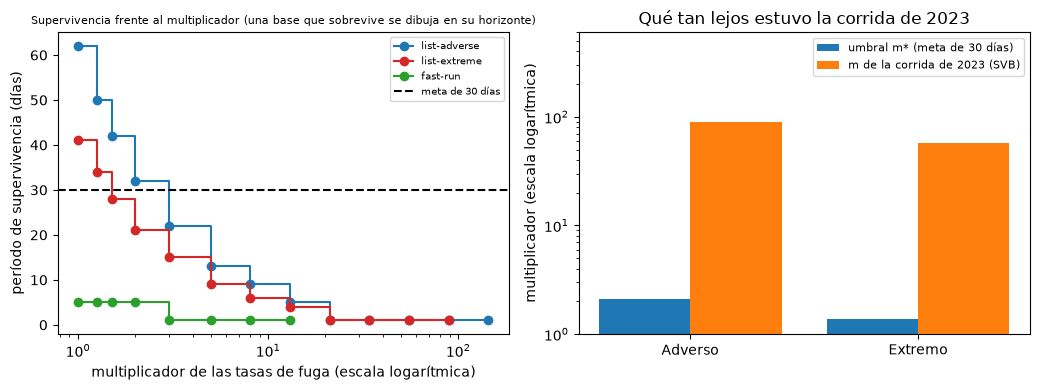

In [7]:
# La verificación de verdad conocida versionada, y luego las curvas de supervivencia con sus umbrales y la distancia a la corrida de 2023
verification = documents["models-svb-liquidity"]["fit"]["generator"]["verification"]
truth_row = next(entry for entry in documents["fast-run"]["tests"] if entry["test_id"] == "liq.runoff_vs_generator_truth")
print("verificación del generador: simulaciones, mayor error, error estándar, dentro del error:", verification["n_draws"], round(verification["max_abs_error"], 6), round(verification["mc_standard_error"], 6), ("sí" if verification["within_error"] else "no"))
print("fila de prueba: mayor distancia en errores estándar y semáforo:", round(truth_row["statistic"], 4), truth_row["light"])

fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 4.0))
grid_all = conventions["runoff_multiplier_grid"]["values"]
for (base_id, (scenario, effective_cbc)), color in zip(built.items(), ("tab:blue", "tab:red", "tab:green")):
    grid = np.array([m for m in grid_all if m <= max_multiplier(scenario)])
    days = [scenario.horizon if r.survives else r.day for r in survival_vs_multiplier(scenario, effective_cbc, grid)]
    left.step(grid, days, where="post", marker="o", color=color, label=base_id)
left.axhline(target, color="black", linestyle="--", label="meta de 30 días")
left.set_xscale("log")
left.set_xlabel("multiplicador de las tasas de fuga (escala logarítmica)")
left.set_ylabel("período de supervivencia (días)")
left.set_title("Supervivencia frente al multiplicador (una base que sobrevive se dibuja en su horizonte)", fontsize=8)
left.legend(fontsize=7)

positions = np.arange(2)
right.bar(positions - 0.2, [distance[b][0] for b in distance], width=0.4, label="umbral m* (meta de 30 días)")
right.bar(positions + 0.2, [distance[b][1] for b in distance], width=0.4, label="m de la corrida de 2023 (SVB)")
right.set_yscale("log")
right.set_ylim(1, 600)
right.set_xticks(positions)
right.set_xticklabels(["Adverso", "Extremo"])
right.set_ylabel("multiplicador (escala logarítmica)")
right.set_title("Qué tan lejos estuvo la corrida de 2023")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **El umbral.** El motor reproduce los multiplicadores versionados con la meta de 30 días: 2,118175 en la base LiST Adverso y 1,383141 en la base Extremo, iguales a los versionados. Los topes (145,2346 y 93,8765) son más de sesenta veces mayores, así que las respuestas quedan lejos del tope; el período de supervivencia en cada umbral y justo por debajo se imprime en el cuaderno 06.
- **El rechazo y el escalón.** La base de corrida rápida se rechaza con la meta de 30 días y con 5 días, porque ninguna es menor que su horizonte de 5 días, y no devuelve ningún número. Para 4 días el umbral es 2,06764 (4 días en él, 5 justo por debajo); para 3 y 1 días es 2,669936, donde el período de supervivencia salta de 4 días a 1: ningún multiplicador da exactamente 3 días, el motor devuelve el umbral e informa ambos períodos de supervivencia, y el viaje de ida y vuelta sigue verde (0,0).
- **La calibración resguardada.** La tasa calibrada con las cuatro filas anteriores a 2023 es 0,05425839, igual a la versionada, y el motor rechaza una fila de 2023 en una llamada evaluada. Evaluada en marzo de 2023, la corrida rápida modela 0,1708 frente al 0,85 de SVB (un error de 0,6792), 0,1263 frente al 0,30 de SVB UK (0,1737) y 0,1263 frente al 0,20 de Signature (0,0737); en una fila con la que se calibró, Northern Rock, cubre de más en 0,0528. Las razones de la contrastación son 0,200976 y 0,214124, rojo. La guarda funciona y el resultado no es halagador: la corrida de 2023 fue más rápida que cualquiera anterior en la Tabla A.1. El generador que respalda al estimador se verificó con 20.000 simulaciones, con un error máximo de 0,00026 frente a un error estándar de 0,000484, y su fila de prueba marca 0,5369, verde.
- **La distancia a la corrida de 2023.** El multiplicador que lleva la tasa LiST de la clase corporativa no asegurada a la tasa de SVB es 88,9855 en la base Adversa y 57,5183 en la Extrema, y con esos multiplicadores el período de supervivencia es de 1 día en ambas. Frente a los umbrales de 2,118175 y 1,383141 las razones son 42,01 y 41,59: la corrida de 2023 estuvo unas cuarenta veces más lejos de las tasas LiST que la meta de 30 días. Una prueba de tensión que se supera con un multiplicador de 2 dice poco de un banco que puede enfrentar un multiplicador de 89.

Dónde se detiene la afirmación. El banco es real en agregado y sintético en comportamiento y depósitos: los multiplicadores muestran el método con esos parámetros, no la holgura del banco. La meta, la grilla de multiplicadores, el calendario de monetización y la regla de calibración son convenciones declaradas del producto (los dosieres no fijan ninguna). El multiplicador escala las tasas de todos los segmentos a la vez; no dice qué segmento, ni qué día, se rompe primero. Y la ausencia de una herramienta previa es UNVERIFIED más allá de la búsqueda del dosier.

## Resumen

- BS-11 se demuestra con evidencia versionada: los multiplicadores 2,118175 (Adverso) y 1,383141 (Extremo) son umbrales que el motor reproduce, con el período de supervivencia en ellos y justo debajo.
- Una meta que no puede acotarse se rechaza con su razón, y un escalón del período de supervivencia más allá de la meta se informa, no se esconde.
- La corrida rápida se calibra antes de 2023 y se evalúa en 2023 por una regla del código; evaluada en SVB queda corta, y el ancla nunca es un pronóstico.
- El multiplicador lee la distancia entre una prueba de tensión y una corrida real: la meta de 30 días es un múltiplo pequeño de las tasas de LiST, y la corrida de 2023 está unas cuarenta veces más lejos.

**Qué probar a continuación.** Resuelve la base Adversa para una meta de 14 días y compara su multiplicador con el de la corrida de 2023; luego lee la sección del SDD sobre las afirmaciones del producto.

## Referencias

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- BCBS (2008), Principles for sound liquidity risk management and supervision, Principle 10. https://www.bis.org/publ/bcbs144.htm
- BCBS (2023), Report on the 2023 banking turmoil, Box A, Table A.1. https://www.bis.org/bcbs/publ/d555.htm
- Federal Reserve Board (2023-04-28), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf